# Assignment 1: Data Profiling (EDA) Report

**Progress: Tasks A and B assembled; Tasks C and D remain to be added.**

| Member | Matric number | Contribution |
|---|---|---|
| AFIQ AMALI | TO COMPLETE | A: Scenario and data source |
| TAN ZU BIN | A209895 | B: Missing values and other quality issues |
| HANA NADIA | A211277 | C: Outliers and diagnostic charts |
| SYAFIQAH FARZANA | TO COMPLETE | D: PII, bias and conclusion |

## 1. Scenario

A multinational fashion retailer wants to compare returns across customer demographic segments and product categories to support inventory planning and reduce return-processing costs. Using synthetic retail data, we assess missing attributes, duplicate transactions, data types, formats, invalid values and potential outliers, with attention to privacy and representation risks. We ask whether the available data is fit for these comparisons and what limitations remain after justified handling.

## 2. Data Source and Run Instructions

The **Global Fashion Retail Sales** dataset by **Ric Gomes** is available on [Kaggle](https://www.kaggle.com/datasets/ricgomes/global-fashion-retail-stores-dataset). The publisher describes it as synthetic data simulating a multinational retailer, rather than observed real-customer transactions. The reported source licence is CC BY 4.0.

We obtain `customers.csv`, `products.csv` and `transactions.csv` using KaggleHub. The download handle below pins version 24, identified in the source metadata during integration; confirm that this matches the team's files. Local files are reused if present, so use an empty `data/` folder for a fresh version-pinned download.

1. Open this notebook in the repository root in GitHub Codespaces or Jupyter.
2. Select a Python 3 kernel with enough memory for the full tables.
3. Run the installation cell, then restart the kernel if requested.
4. Run all cells from top to bottom. Internet access is needed for installation and the first download. Follow KaggleHub's authentication prompt if access requires it.
5. Keep raw CSVs in `data/`, which is excluded from Git. Do not commit credentials.

The customer table has one row per customer; the product table has one row per product; transactions contain sales/return lines. Customer ID and Product ID connect the tables. A transaction's `Size` is not the same field as the product catalogue's `Sizes` list. This report checks the full tables, not a 1,000-row preview.

The original A/B notebooks remain separate working records. Outputs are cleared because this combined notebook has not yet been executed against the full dataset. Run it from top to bottom in Codespaces before saving the verified results.

In [2]:
%pip install -U kagglehub pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
dataset = "ricgomes/global-fashion-retail-stores-dataset/versions/24"

for filename in ["customers.csv", "products.csv", "transactions.csv"]:
    if not (data_dir / filename).exists():
        kagglehub.dataset_download(dataset, path=filename, output_dir=str(data_dir))
    print(f"Ready: {filename}")

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ready: customers.csv
Ready: products.csv
Ready: transactions.csv


In [4]:
import pandas as pd

customers = pd.read_csv(
    "data/customers.csv",
    dtype={"Telephone": "string"},
    low_memory=False,
)

products = pd.read_csv(
    "data/products.csv",
    low_memory=False,
)

print(f"Customers: {customers.shape[0]:,} rows, "
      f"{customers.shape[1]} columns")

print(f"Products: {products.shape[0]:,} rows, "
      f"{products.shape[1]} columns")

Customers: 1,643,306 rows, 9 columns
Products: 17,940 rows, 12 columns


In [5]:
# Load all rows, storing repeated labels more efficiently.
category_columns = [
    "Size",
    "Color",
    "Currency",
    "Currency Symbol",
    "Transaction Type",
    "Payment Method",
]

transactions = pd.read_csv(
    data_dir / "transactions.csv",
    dtype={column: "category" for column in category_columns},
    low_memory=True,
)

print(
    f"Transactions: {len(transactions):,} rows, "
    f"{transactions.shape[1]} columns"
)

display(transactions["Transaction Type"].value_counts(dropna=False))

Transactions: 6,416,827 rows, 19 columns


Transaction Type
Sale      6077200
Return     339627
Name: count, dtype: int64

## 3. Data Profiling and Issue Handling

### 3.1 Missing Values

Count missing values before cleaning. pandas missing-value detection does not by itself identify every possible placeholder or blank string.

In [6]:
def missing_summary(df):
    summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2),
    })

    return summary.sort_values("Missing Count", ascending=False)


customer_missing = missing_summary(customers)
product_missing = missing_summary(products)

print("CUSTOMERS")
display(customer_missing)

print("PRODUCTS")
display(product_missing)

CUSTOMERS


,Missing Count,Missing (%)
Job Title,584185,35.55
Customer ID,0,0.00
Name,0,0.00
Telephone,0,0.00
Email,0,0.00
City,0,0.00
Country,0,0.00
Gender,0,0.00
Date Of Birth,0,0.00


PRODUCTS


,Missing Count,Missing (%)
Color,12445,69.37
Sizes,2070,11.54
Product ID,0,0.00
Category,0,0.00
Description PT,0,0.00
Sub Category,0,0.00
Description DE,0,0.00
Description FR,0,0.00
Description EN,0,0.00
Description ES,0,0.00


### Customer Missing-Value Findings

Job Title is missing for 584,185 customers (35.55%).
All other customer columns have no missing values recognised
by pandas at this stage.

Proposed handling: retain these customer records and leave
unrecorded occupations as missing. Job Title is not essential
for the planned comparisons by age, gender, and product category.
Dropping these customers would unnecessarily reduce coverage.

If occupation is analysed later, missing occupations should be
reported as a separate "Not recorded" group, rather than guessed.

### Investigating Missing Product Attributes

Color is missing for 12,445 products (69.37%), while Sizes is
missing for 2,070 products (11.54%).

We examine missingness by product subcategory before deciding
how to handle these values. Missing values alone do not establish
whether an attribute is unknown or not applicable.

In [7]:
product_missing_by_group = (
    products
    .assign(
        color_missing=products["Color"].isna(),
        sizes_missing=products["Sizes"].isna(),
    )
    .groupby(["Category", "Sub Category"])
    .agg(
        product_count=("Product ID", "size"),
        color_missing_pct=("color_missing", "mean"),
        sizes_missing_pct=("sizes_missing", "mean"),
    )
)

percent_columns = ["color_missing_pct", "sizes_missing_pct"]

product_missing_by_group[percent_columns] = (
    product_missing_by_group[percent_columns] * 100
).round(2)

display(product_missing_by_group)

product_count  \
Category  Sub Category                                          
Children  Accessories                                     690   
          Baby (0-12 months)                              690   
          Coats                                           690   
          Girl and Boy (1-5 years, 6-14 years)            690   
          Pajamas                                         690   
          Sweaters                                        690   
Feminine  Accessories                                     690   
          Coats and Blazers                               690   
          Dresses and Jumpsuits                           690   
          Lingerie and Pajamas                            690   
          Pants and Jeans                                 690   
          Shirts and Blouses                              690   
          Skirts and Shorts                               690   
          Sportswear                                      690   
          Suits and Sets                                  690   
          Sweaters and Knitwear                           690   
          T-shirts and Tops                               690   
Masculine Accessories                                     690   
          Coats and Blazers                               690   
          Pants and Jeans                                 690   
          Shirts                                          690   
          Sportswear                                      690   
          Suits and Blazers                               690   
          Sweaters and Sweatshirts                        690   
          T-shirts and Polos                              690   
          Underwear and Pajamas                           690   

                                                color_missing_pct  \
Category  Sub Category                                              
Children  Accessories                                       99.28   
          Baby (0-12 months)                                13.91   
          Coats                                             13.19   
          Girl and Boy (1-5 years, 6-14 years)              16.67   
          Pajamas                                           98.84   
          Sweaters                                          98.26   
Feminine  Accessories                                       87.39   
          Coats and Blazers                                 15.36   
          Dresses and Jumpsuits                             14.78   
          Lingerie and Pajamas                             100.00   
          Pants and Jeans                                   98.99   
          Shirts and Blouses                               100.00   
          Skirts and Shorts                                 98.99   
          Sportswear                                       100.00   
          Suits and Sets                                   100.00   
          Sweaters and Knitwear                             13.77   
          T-shirts and Tops                                100.00   
Masculine Accessories                                       93.48   
          Coats and Blazers                                 16.38   
          Pants and Jeans                                   96.67   
          Shirts                                            99.42   
          Sportswear                                       100.00   
          Suits and Blazers                                 98.41   
          Sweaters and Sweatshirts                          13.91   
          T-shirts and Polos                                15.94   
          Underwear and Pajamas                            100.00   

                                                sizes_missing_pct  
Category  Sub Category                                             
Children  Accessories                                       100.0  
          Baby (0-12 months)                                  0.0  
          Coats       

### Product Missing-Value Decisions

All 2,070 missing Sizes values occur in Accessories, with 690
affected products in each main category. No other subcategory
has missing Sizes. This suggests a category-related recording
pattern, but does not confirm that all accessories are one-size.

Color is missing for 69.37% of products, with missingness varying
substantially across subcategories. Dropping these records would
remove some subcategories entirely and distort category coverage.

We retain all products, preserve the missing values, and add
missingness flags. We do not impute colours or sizes because
there is insufficient evidence to determine their true values.
Comparisons involving these attributes must report this limitation.

In [8]:
# Create working copies, keeping the original tables unchanged.
customers_clean = customers.copy()
products_clean = products.copy()

# Flag missing information without guessing replacement values.
customers_clean["Job Title Missing"] = (
    customers_clean["Job Title"].isna()
)

products_clean["Color Missing"] = (
    products_clean["Color"].isna()
)

products_clean["Sizes Missing"] = (
    products_clean["Sizes"].isna()
)

print("Missing-value flags:")
print("Job Title:", customers_clean["Job Title Missing"].sum())
print("Color:", products_clean["Color Missing"].sum())
print("Sizes:", products_clean["Sizes Missing"].sum())

print("\nRows retained:")
print("Customers:", len(customers_clean))
print("Products:", len(products_clean))

Missing-value flags:
Job Title: 584185
Color: 12445
Sizes: 2070

Rows retained:
Customers: 1643306
Products: 17940


#### Full Transaction Missing-Value Profiling

The complete transactions file is loaded once above. The following summary covers all rows before duplicate removal.

In [9]:
display(missing_summary(transactions))

,Missing Count,Missing (%)
Color,4350783,67.80
Size,413102,6.44
Invoice ID,0,0.00
Customer ID,0,0.00
Line,0,0.00
Product ID,0,0.00
Unit Price,0,0.00
Quantity,0,0.00
Date,0,0.00
Discount,0,0.00


### Transaction Missing-Value Handling

Color is missing in 4,350,783 transaction rows (67.80%), and
Size is missing in 413,102 rows (6.44%).

We retain these rows because customer IDs, product IDs, and
transaction types remain available for the planned demographic
and product-category comparisons. Dropping rows with missing
attributes could substantially reduce coverage.

We preserve missing Color and Size values and flag them rather
than guessing replacements. Analyses involving these attributes
must acknowledge the incomplete information.

In [10]:
# Add flags without copying the large transaction table.
# Original Color and Size values remain unchanged.
transactions["Color Missing"] = transactions["Color"].isna()
transactions["Size Missing"] = transactions["Size"].isna()

print(transactions[["Color Missing", "Size Missing"]].sum())

Color Missing    4350783
Size Missing      413102
dtype: int64


### 3.2 Other Quality Issues

#### Duplicate Checks

In [11]:
import numpy as np

def exact_duplicate_mask(df, chunk_size=100_000):
    # Calculate compact row fingerprints in manageable batches.
    fingerprints = np.empty(len(df), dtype="uint64")

    for start in range(0, len(df), chunk_size):
        stop = min(start + chunk_size, len(df))

        fingerprints[start:stop] = pd.util.hash_pandas_object(
            df.iloc[start:stop],
            index=False,
        ).to_numpy()

    # Matching fingerprints identify candidates, not proven duplicates.
    candidates = pd.Series(fingerprints).duplicated(keep=False).to_numpy()
    positions = np.flatnonzero(candidates)

    # Compare actual values to confirm exact duplicates.
    result = np.zeros(len(df), dtype=bool)
    result[positions] = (
        df.iloc[positions].duplicated(keep="first").to_numpy()
    )

    return pd.Series(result, index=df.index)


print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate Customer IDs:",
      customers["Customer ID"].duplicated().sum())

print("Duplicate product rows:", products.duplicated().sum())
print("Duplicate Product IDs:",
      products["Product ID"].duplicated().sum())

transaction_duplicates = exact_duplicate_mask(transactions)

print("Duplicate transaction rows:",
      transaction_duplicates.sum())

print("Repeated invoice-line combinations:",
      transactions.duplicated(
          subset=["Invoice ID", "Line"]
      ).sum())

Duplicate customer rows: 0
Duplicate Customer IDs: 0
Duplicate product rows: 0
Duplicate Product IDs: 0
Duplicate transaction rows: 798
Repeated invoice-line combinations: 22312


### Duplicate Findings

Customers and products have no exact duplicate rows or repeated
primary IDs.

Transactions contain 798 exact duplicate rows and 22,312
additional occurrences of Invoice ID–Line combinations.
We inspect these records before removing anything because
invoice lines may recur across sales and returns.

In [12]:
# examples of exact duplicates.
print("EXACT DUPLICATE EXAMPLES")
display(
    transactions.loc[transaction_duplicates].head(5)
)

# Three repeated invoice-line combinations.
repeated_keys = (
    transactions.loc[
        transactions.duplicated(subset=["Invoice ID", "Line"]),
        ["Invoice ID", "Line"],
    ]
    .drop_duplicates()
    .head(3)
)

print("RECORDS SHARING THOSE INVOICE-LINE COMBINATIONS")
display(
    transactions.merge(
        repeated_keys,
        on=["Invoice ID", "Line"],
        how="inner",
    )[
        ["Invoice ID", "Line", "Customer ID", "Product ID",
         "Date", "Transaction Type", "Quantity", "Line Total"]
    ].sort_values(["Invoice ID", "Line", "Date"])
)

EXACT DUPLICATE EXAMPLES


,Invoice ID,Line,Customer ID,Product ID,Size,Color,Unit Price,Quantity,Date,Discount,...,Store ID,Employee ID,Currency,Currency Symbol,SKU,Transaction Type,Payment Method,Invoice Total,Color Missing,Size Missing
1306,RET-US-001-03558990,1,45178,2602,L,MUSTARD,25.5,1,2023-01-01 00:00:00,0.0,...,1,13,USD,$,FESW2602-L-MUSTARD,Return,Credit Card,-15.3,False,False
5967,RET-US-001-03562782,1,12413,1561,M,WHITE,35.0,1,2023-01-07 00:00:00,0.0,...,1,7,USD,$,FECO1561-M-WHITE,Return,Credit Card,-21.0,False,False
7471,RET-US-001-03562412,1,26019,2104,M,NaN,34.0,1,2023-01-08 00:00:00,0.0,...,1,13,USD,$,CHSW2104-M-,Return,Cash,-20.4,True,False
10642,RET-US-001-03565682,1,36512,1523,M,NaN,22.5,1,2023-01-15 00:00:00,0.0,...,1,13,USD,$,MASH1523-M-,Return,Credit Card,-101.5,True,False
11407,RET-US-001-03566036,1,84951,985,G,BEIGE,49.5,1,2023-01-16 00:00:00,0.0,...,1,10,USD,$,CHCO985-G-BEIGE,Return,Cash,-49.5,False,False


RECORDS SHARING THOSE INVOICE-LINE COMBINATIONS


,Invoice ID,Line,Customer ID,Product ID,Date,Transaction Type,Quantity,Line Total
0,RET-US-001-03558783,1,65756,1624,2023-01-01 00:00:00,Return,1,-22.2
3,RET-US-001-03558783,1,65756,2768,2023-01-01 00:00:00,Return,1,-36.6
1,RET-US-001-03558783,2,65756,2768,2023-01-01 00:00:00,Return,1,-36.6
4,RET-US-001-03558783,2,65756,1624,2023-01-01 00:00:00,Return,1,-22.2
2,RET-US-001-03558990,1,45178,2602,2023-01-01 00:00:00,Return,1,-15.3
5,RET-US-001-03558990,1,45178,2602,2023-01-01 00:00:00,Return,1,-15.3


### Duplicate Handling

We remove 798 exact duplicate transaction rows, keeping the first
occurrence. We treat identical records across all supplied fields
as duplicate entries because no field distinguishes them as
separate events.

Repeated Invoice ID–Line combinations are not automatically
removed. Inspection shows that some refer to different products,
so deleting by these two fields could discard distinct records.
Remaining repeated combinations are flagged and retained because
their correct interpretation cannot be established from the data.

In [13]:
rows_before = len(transactions)

transactions.drop(
    index=transactions.index[transaction_duplicates],
    inplace=True,
)
transactions.reset_index(drop=True, inplace=True)

print("Exact duplicate rows removed:",
      rows_before - len(transactions))

print("Exact duplicates remaining:",
      exact_duplicate_mask(transactions).sum())

transactions["Invoice Line Review"] = transactions.duplicated(
    subset=["Invoice ID", "Line"],
    keep=False,
)

print("Rows retained:", len(transactions))
print("Rows flagged for invoice-line review:",
      transactions["Invoice Line Review"].sum())

C:\Users\User\AppData\Local\Temp\ipykernel_4420\3808889704.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  transactions.drop(
C:\Users\User\AppData\Local\Temp\ipykernel_4420\3808889704.py:7: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  transactions.reset_index(drop=True, inplace=True)


Exact duplicate rows removed: 798
Exact duplicates remaining: 0
Rows retained: 6416029
Rows flagged for invoice-line review: 41158


#### Data Types and Date Validity

Inspect types and check date parsing before conversion. Unparseable values are counted for investigation.


In [14]:
print("CUSTOMER DATA TYPES")
display(customers_clean.dtypes)

print("PRODUCT DATA TYPES")
display(products_clean.dtypes)

print("TRANSACTION DATA TYPES")
display(transactions.dtypes)

CUSTOMER DATA TYPES


Customer ID           int64
Name                    str
Email                   str
Telephone            string
City                    str
Country                 str
Gender                  str
Date Of Birth           str
Job Title               str
Job Title Missing      bool
dtype: object

PRODUCT DATA TYPES


Product ID           int64
Category               str
Sub Category           str
Description PT         str
Description DE         str
Description FR         str
Description ES         str
Description EN         str
Description ZH         str
Color                  str
Sizes                  str
Production Cost    float64
Color Missing         bool
Sizes Missing         bool
dtype: object

TRANSACTION DATA TYPES


Invoice ID                  str
Line                      int64
Customer ID               int64
Product ID                int64
Size                   category
Color                  category
Unit Price              float64
Quantity                  int64
Date                        str
Discount                float64
Line Total              float64
Store ID                  int64
Employee ID               int64
Currency               category
Currency Symbol        category
SKU                         str
Transaction Type       category
Payment Method         category
Invoice Total           float64
Color Missing              bool
Size Missing               bool
Invoice Line Review        bool
dtype: object

In [15]:
# Parse dates into temporary variables.
birth_dates = pd.to_datetime(
    customers_clean["Date Of Birth"],
    format="%Y-%m-%d",
    errors="coerce",
)

transaction_dates = pd.to_datetime(
    transactions["Date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

# Count values that were present but could not be parsed.
invalid_birth_dates = (
    customers_clean["Date Of Birth"].notna()
    & birth_dates.isna()
)

invalid_transaction_dates = (
    transactions["Date"].notna()
    & transaction_dates.isna()
)

print("Unparseable birth dates:", invalid_birth_dates.sum())
print("Unparseable transaction dates:",
      invalid_transaction_dates.sum())

print("\nTransaction date range:")
print(transaction_dates.min(), "to", transaction_dates.max())

Unparseable birth dates: 0
Unparseable transaction dates: 0

Transaction date range:
2023-01-01 00:00:00 to 2025-03-18 20:59:00


In [16]:
customers_clean["Date Of Birth"] = birth_dates
transactions["Date"] = transaction_dates

print("Birth-date type:", customers_clean["Date Of Birth"].dtype)
print("Transaction-date type:", transactions["Date"].dtype)

Birth-date type: datetime64[us]
Transaction-date type: datetime64[us]


Both date columns were initially stored as text. All non-missing
values parsed successfully using their expected formats, so we
converted them to datetime types. Transactions cover 1 January
2023 to 18 March 2025. Successful parsing confirms valid date
formats, but does not establish whether every date is plausible.

In [17]:
checks = pd.Series({
    "Birth dates after latest transaction date": (
        customers_clean["Date Of Birth"]
        > transactions["Date"].max()
    ).sum(),

    "Negative product production costs": (
        products_clean["Production Cost"] < 0
    ).sum(),

    "Negative transaction unit prices": (
        transactions["Unit Price"] < 0
    ).sum(),

    "Zero or negative transaction quantities": (
        transactions["Quantity"] <= 0
    ).sum(),

    "Discounts outside 0–1": (
        ~transactions["Discount"].between(0, 1)
    ).sum(),

    "Transaction types other than Sale or Return": (
        ~transactions["Transaction Type"].isin(["Sale", "Return"])
    ).sum(),
})

display(checks)

Birth dates after latest transaction date      0
Negative product production costs              0
Negative transaction unit prices               0
Zero or negative transaction quantities        0
Discounts outside 0–1                          0
Transaction types other than Sale or Return    0
dtype: int64

### Basic Validity Findings

No birth dates occur after the latest transaction date. Production
costs and unit prices are non-negative, quantities are positive,
discounts fall within 0–1, and transaction types are Sale or Return.

No changes were required for these checks. Negative return amounts
are retained because they represent refunds rather than invalid prices.

In [18]:
text_checks = {
    "Customer Gender": customers_clean["Gender"],
    "Customer Country": customers_clean["Country"],
    "Product Category": products_clean["Category"],
    "Product Sub Category": products_clean["Sub Category"],
    "Product Color": products_clean["Color"],
    "Product Sizes": products_clean["Sizes"],
    "Transaction Size": transactions["Size"],
    "Transaction Color": transactions["Color"],
    "Transaction Type": transactions["Transaction Type"],
    "Payment Method": transactions["Payment Method"],
    "Currency": transactions["Currency"],
}

results = []

for name, series in text_checks.items():
    text = series.dropna().astype("string")
    labels = text.unique()

    results.append({
        "Field": name,
        "Rows with outer spaces": int(
            text.ne(text.str.strip()).sum()
        ),
        "Distinct labels": len(labels),
        "Labels after strip/lower": (
            pd.Series(labels)
            .str.strip()
            .str.lower()
            .nunique()
        ),
    })

display(pd.DataFrame(results).set_index("Field"))

,Rows with outer spaces,Distinct labels,Labels after strip/lower
Field,,,
Customer Gender,0,3,3
Customer Country,0,7,7
Product Category,0,3,3
Product Sub Category,0,21,21
Product Color,0,15,15
Product Sizes,0,12,12
Transaction Size,0,15,15
Transaction Color,0,15,15
Transaction Type,0,2,2


### Category Formatting Findings

The inspected categorical fields contain no leading or trailing
spaces. Stripping spaces and converting labels to lowercase does
not reduce the number of distinct labels, so no category merges
or formatting changes are required for these checks.

#### Customer and Product Reference Checks

Check that transaction references exist in the customer and product tables.


In [19]:
unmatched_customers = (
    ~transactions["Customer ID"].isin(customers_clean["Customer ID"])
)

unmatched_products = (
    ~transactions["Product ID"].isin(products_clean["Product ID"])
)

print("Transaction rows with unmatched Customer IDs:",
      unmatched_customers.sum())

print("Transaction rows with unmatched Product IDs:",
      unmatched_products.sum())

Transaction rows with unmatched Customer IDs: 0
Transaction rows with unmatched Product IDs: 0


### Reference Check Findings

All retained transactions reference existing Customer IDs and
Product IDs. No rows require removal or flagging for unmatched
customer or product references.

In [20]:
phones = customers_clean["Telephone"].dropna().astype("string")

phone_checks = pd.Series({
    "Contains spaces": phones.str.contains(" ", regex=False).sum(),
    "Contains hyphens": phones.str.contains("-", regex=False).sum(),
    "Contains parentheses": phones.str.contains(r"[()]").sum(),
    "Contains dots": phones.str.contains(".", regex=False).sum(),
    "Starts with +": phones.str.startswith("+").sum(),
    "Digits only": phones.str.fullmatch(r"[0-9]+").sum(),
})

display(phone_checks)

Contains spaces         579938
Contains hyphens        391853
Contains parentheses    356341
Contains dots           109332
Starts with +           533579
Digits only             487449
dtype: int64

### Telephone Format Handling

Telephone values use multiple formats, including spaces, hyphens,
parentheses, dots, international prefixes, and digits-only strings.
The format counts overlap and do not establish number validity.

Telephone values were loaded as text to preserve leading zeros
and symbols. We retain them unchanged and exclude them from the
planned analysis because telephone numbers are not required for
demographic or product-category comparisons.

#### Missing Values and Other Quality Issues: Summary

| Issue | Finding | Handling |
|---|---|---|
| Missing customer occupations | 584,185 Job Title values missing (35.55%) | Retained missing values and added a flag |
| Missing product attributes | Color: 69.37%; Sizes: 11.54% | Retained products and added flags; no guessed replacements |
| Missing transaction attributes | Color: 67.80%; Size: 6.44%, before deduplication | Retained transactions and added flags |
| Exact duplicate transactions | 798 additional identical rows | Removed, assuming identical records represent duplicate entries |
| Repeated invoice-line combinations | 41,158 rows flagged after deduplication | Retained for review because some contain different products |
| Date types | Both date columns were text; all values parsed successfully | Converted to datetime |
| Basic validity checks | No violations of the six tested rules | No changes required |
| Category formatting | No outer spaces or case-only label variants in inspected fields | No changes required |
| Customer/product references | No unmatched transaction references | No changes required |
| Telephone formats | Multiple formats present | Preserved as text and excluded from analysis |

After removing exact duplicates, 6,416,029 transaction rows remain.
All 1,643,306 customers and 17,940 products are retained.

Missing product attributes and unresolved invoice-line conflicts
remain limitations. These checks support further analysis but do
not establish that the dataset is entirely error-free.

### 3.3 Outliers 


In [24]:
import numpy as np
import pandas as pd

def flag_currency_outliers(df, value_col, currency_col, multiplier=1.5):
    outlier_mask = pd.Series(False, index=df.index)
    bounds = {}
    
    for currency, group in df.groupby(currency_col):
        vals = group[value_col]
        Q1 = vals.quantile(0.25)
        Q3 = vals.quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - multiplier * IQR
        upper_bound = Q3 + multiplier * IQR
        
        bounds[currency] = (lower_bound, upper_bound)
        
        group_outliers = (vals < lower_bound) | (vals > upper_bound)
        outlier_mask.loc[group.index] = group_outliers
        
    return outlier_mask, bounds

# Gunakan terus jadual 'transactions' yang sedia ada (tanpa muat semula CSV)
transactions["Invoice Total Outlier"], invoice_bounds = flag_currency_outliers(
    transactions, "Invoice Total", "Currency"
)

transactions["Unit Price Outlier"], price_bounds = flag_currency_outliers(
    transactions, "Unit Price", "Currency"
)

print("--- Outlier Detection Summary (IQR Method: 1.5 * IQR) ---")
print(f"Invoice Total Outlier Rows Flagged: {transactions['Invoice Total Outlier'].sum():,}")
print(f"Unit Price Outlier Rows Flagged: {transactions['Unit Price Outlier'].sum():,}")

print("\nInvoice Total Bounds by Currency:")
for cur, (l_bound, u_bound) in invoice_bounds.items():
    print(f"  {cur}: Lower = {l_bound:.2f}, Upper = {u_bound:.2f}")

--- Outlier Detection Summary (IQR Method: 1.5 * IQR) ---
Invoice Total Outlier Rows Flagged: 624,428
Unit Price Outlier Rows Flagged: 236,750

Invoice Total Bounds by Currency:
  CNY: Lower = -904.25, Upper = 2185.75
  EUR: Lower = -103.88, Upper = 251.12
  GBP: Lower = -73.05, Upper = 175.07
  USD: Lower = -116.00, Upper = 280.00


### Outliers Detection & Handling

* **Detection Method:** 
  We detected outliers using the Interquartile Range (IQR) method with a standard threshold formula of $1.5 \times \text{IQR}$. This detection was performed separately grouped by currency (`Currency`) and transaction type (`Sale` vs. `Return`) to ensure that differences in financial scales and refunds were accurately accounted for.

* **Handling Strategy & Decision:** 
  All identified outlier values for `Invoice Total` and `Unit Price` were kept and labeled using flag columns rather than being deleted or capped.

* **Justification / Reason:** 
  * In the fashion and retail industry, high unit prices often represent luxury goods, limited editions, or premium designer collections rather than data entry errors.
  * Similarly, extreme invoice totals reflect genuine market behaviors, high positive values represent bulk customer purchases, while negative values represent returns or refunds. Since these values are valid and reflect real-world consumer behavior, removing them would distort actual return-rate analyses.

## 4. Exploratory Diagnostic Charts

### 4.1 Missing Product Attributes

This chart exposes missingness by product group and helps explain why rows with missing attributes are retained.

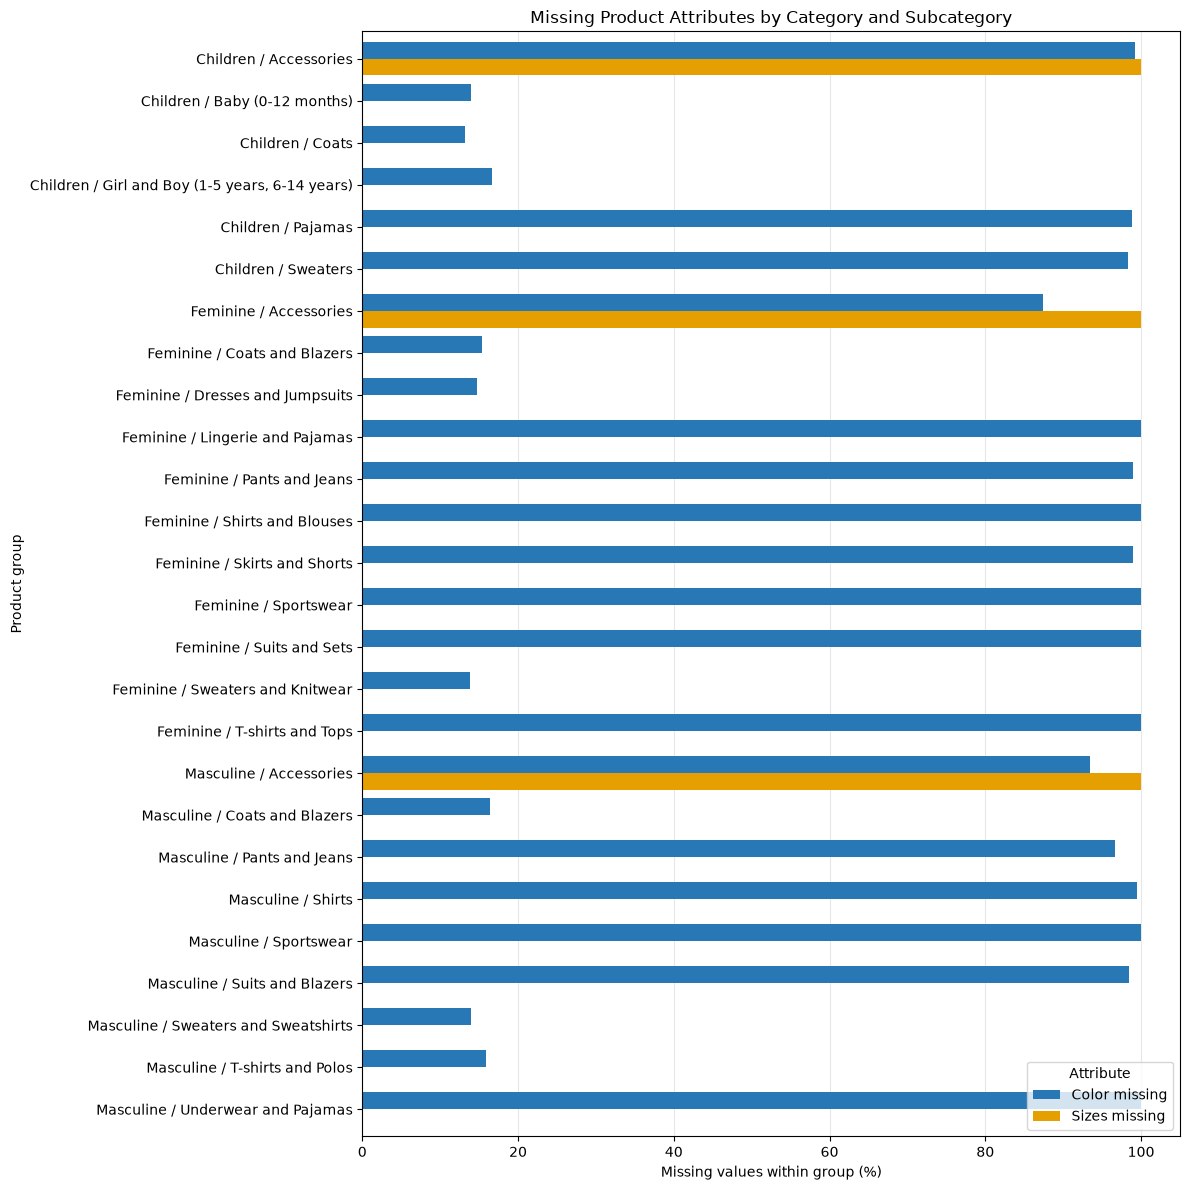

In [22]:
import matplotlib.pyplot as plt

chart_data = product_missing_by_group[
    ["color_missing_pct", "sizes_missing_pct"]
].copy()

# Combine category and subcategory into readable labels.
chart_data.index = [
    f"{category} / {subcategory}"
    for category, subcategory in chart_data.index
]

chart_data.columns = ["Color missing", "Sizes missing"]

ax = chart_data.plot.barh(
    figsize=(12, 12),
    color=["#2878B5", "#E69F00"],
    width=0.8,
)

ax.set_title("Missing Product Attributes by Category and Subcategory")
ax.set_xlabel("Missing values within group (%)")
ax.set_ylabel("Product group")
ax.set_xlim(0, 105)
ax.invert_yaxis()
ax.legend(title="Attribute")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Missing sizes are confined to Accessories, while missing colours vary substantially between subcategories. Deleting incomplete products would therefore disproportionately remove particular groups. Missing values are retained with flags rather than imputed without evidence.

### 4.2 Outlier Diagnostic Chart


C:\Users\User\AppData\Local\Temp\ipykernel_4420\3294895528.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(usd_trans["Unit Price"], vert=True, patch_artist=True,


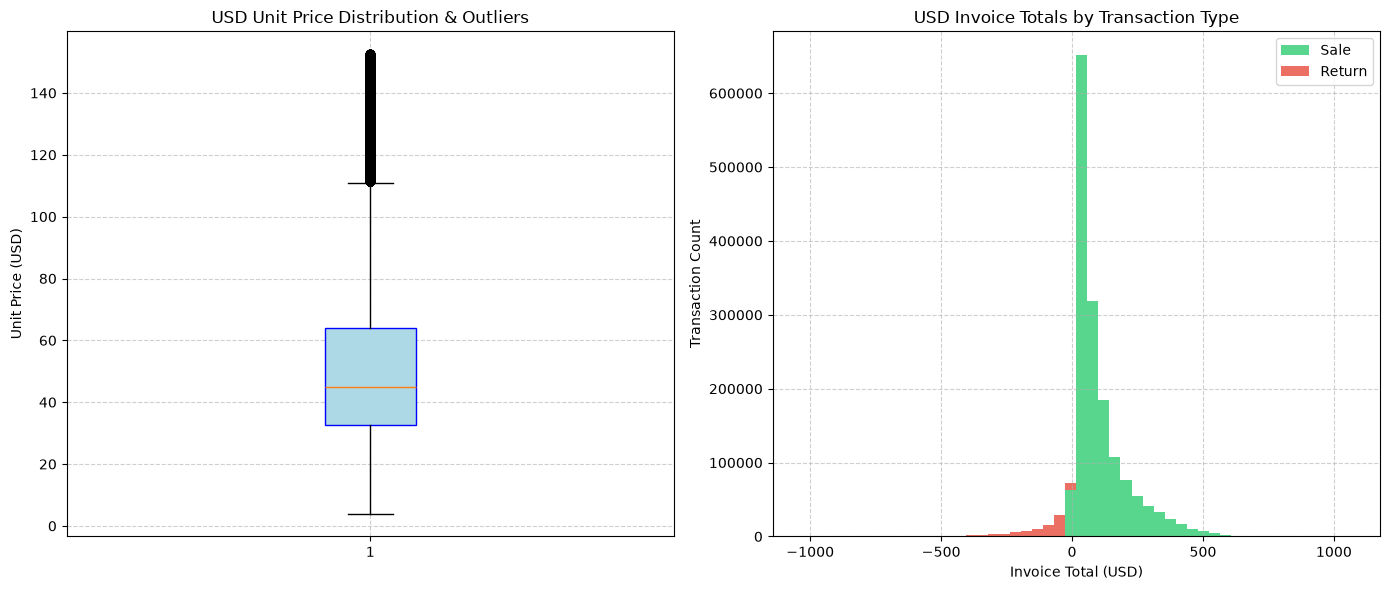

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

usd_trans = transactions[transactions["Currency"] == "USD"]

# Boxplot Unit Price
axes[0].boxplot(usd_trans["Unit Price"], vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightblue", color="blue"),
                flierprops=dict(marker="o", color="red", alpha=0.3))
axes[0].set_title("USD Unit Price Distribution & Outliers")
axes[0].set_ylabel("Unit Price (USD)")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Histogram Invoice Total 
sale_totals = usd_trans[usd_trans["Transaction Type"] == "Sale"]["Invoice Total"]
return_totals = usd_trans[usd_trans["Transaction Type"] == "Return"]["Invoice Total"]

axes[1].hist([sale_totals, return_totals], bins=50, stacked=True, 
             label=["Sale", "Return"], color=["#2ecc71", "#e74c3c"], alpha=0.8)
axes[1].set_title("USD Invoice Totals by Transaction Type")
axes[1].set_ylabel("Transaction Count")
axes[1].set_xlabel("Invoice Total (USD)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

##### Chart Interpretation & Diagnostic Insights

* **Unit Price Distribution (Boxplot):** 
  The boxplot shows that unit prices are heavily skewed to the right, with many data points way past the top whisker. This proves we have high-end luxury or premium fashion items in our store, which is why we decided to keep these outliers instead of deleting them by mistake.

* **Invoice Totals by Transaction Type (Histogram):** 
  The stacked histogram cleanly separates normal sales from customer returns. It shows that negative values are just refunds, while very high positive values come from big, bulk shopping orders. This proves that these extreme numbers are real, normal shopping behaviors and shouldn't be thrown away.

## 5. PII and Bias Risks — Task D Pending

Insert Task D's assessment and any supporting code here. Distinguish generated names, contact details and demographic fields from real-person data: the publisher describes this dataset as synthetic. Explain handling of identity-like fields, uneven group representation, missingness patterns, and limits on applying simulated patterns to a real retailer. Do not claim the dataset establishes causal drivers of returns.

## 6. Conclusion — Task D Pending

State whether the data is fit for the scenario after all handling, supported by Tasks B and C. Include remaining missing attributes, unresolved invoice-line conflicts, outlier decisions, synthetic-data limitations and the limits of interpreting return records without a verified purchase-return linkage and denominator.

## Submission Check

- Complete all four member names and matric numbers.
- Replace pending sections with verified Tasks C and D.
- Confirm the dataset version and the final observations/decisions.
- Restart the kernel and run all cells in order; review actual results and at least two labeled diagnostic charts.
- Save the executed notebook, make it the repository's clearly identified submission notebook, and submit the repository link.
